In [ ]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
data = [
    "cats like milk",
    "dogs like balls",
    "cats drink milk",
    "dogs chase cats"
]

mystery_sentence = "dogs drink milk"


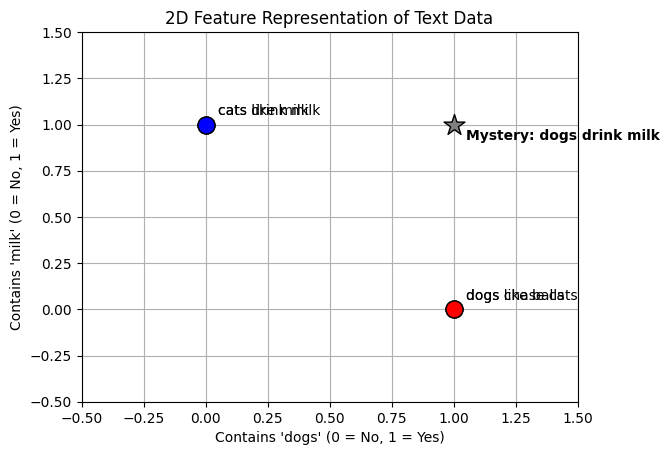

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Helper function to convert our text data into 2D numeric coordinates
def sentence_to_point(sentence):
    x = 1.0 if "dogs" in sentence else 0.0
    y = 1.0 if "milk" in sentence else 0.0
    return [x, y]

# Map our raw text data to numeric coordinates and binary labels
numeric_data = []
for sentence in data:
    point = sentence_to_point(sentence)
    label = 1 if "dogs" in sentence else 0
    numeric_data.append(point + [label])

# Map our mystery sentence
mystery_point = sentence_to_point(mystery_sentence)

def vis_data():
    plt.grid(True)

    # Plot each training sentence
    for i in range(len(numeric_data)):
        point = numeric_data[i]
        c = 'r' if point[2] == 1 else 'b'
        plt.scatter([point[0]], [point[1]], c=c, s=150, edgecolors='black', zorder=3)
        plt.text(point[0] + 0.05, point[1] + 0.05, data[i], fontsize=10)

    # Plot the mystery sentence as a gray star
    plt.scatter([mystery_point[0]], [mystery_point[1]], c='gray', s=250, marker='*', edgecolors='black', zorder=4)
    plt.text(mystery_point[0] + 0.05, mystery_point[1] - 0.08, f"Mystery: {mystery_sentence}", fontsize=10, fontweight='bold')

    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel("Contains 'dogs' (0 = No, 1 = Yes)")
    plt.ylabel("Contains 'milk' (0 = No, 1 = Yes)")
    plt.title("2D Feature Representation of Text Data")

vis_data()
plt.show()

In [ ]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

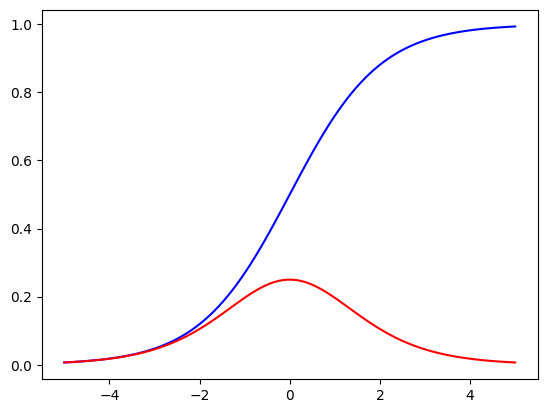

In [ ]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

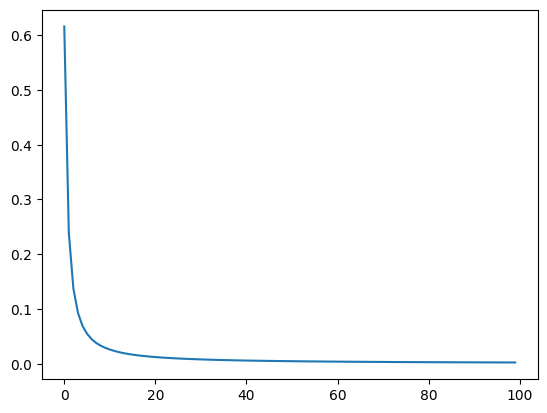

In [ ]:
# train

def train():
    # random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point from the NUMERIC data
        ri = np.random.randint(len(numeric_data))
        point = numeric_data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(numeric_data)):
                p = numeric_data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [ ]:
# predict what the mystery sentence means!

z = w1 * mystery_point[0] + w2 * mystery_point[1] + b
pred = sigmoid(z)

print(f"Prediction probability: {pred:.4f}")
print(f"Sentence: '{mystery_sentence}'")
if pred > 0.5:
    print("Prediction -> Red (Dog-themed text)")
else:
    print("Prediction -> Blue (Cat-themed text)")

Prediction probability: 0.4937
Sentence: 'dogs drink milk'
Prediction -> Blue (Cat-themed text)


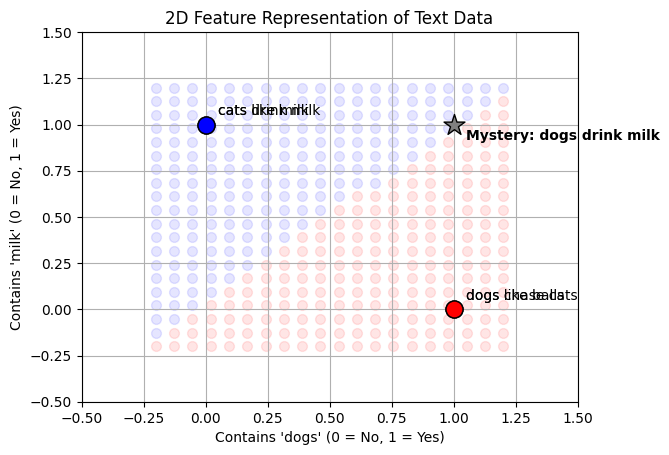

In [ ]:
# check out the networks predictions in the x,y plane for our features
for x in np.linspace(-0.2, 1.2, 20):
    for y in np.linspace(-0.2, 1.2, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.1, s=50)

# plot training points and mystery point over network predictions
vis_data()